# 02.2 — Modules, Data and the Training Loop

How a real PyTorch project is put together: a model class, a dataset, a DataLoader, a loss, the training loop, and checkpoints.
The example trains a classifier on FashionMNIST (photos of clothes).

## What's in this notebook

- 1\. The pieces of a training setup
- 2\. nn.Module: parameters and buffers
- 3\. Containers and the plain-list bug
- 4\. train() and eval() modes
- 5\. The data: download and a custom Dataset
- 6\. Splits and the DataLoader
- 7\. Padding variable-length sequences
- 8\. Loss functions
- 9\. The training loop
- 10\. CPU or GPU?
- 11\. Saving, loading and resuming
- 12\. Test set and predictions
- 13\. Trade-offs
- 14\. Interview questions
- 15\. In my own words

In [1]:
import copy
import gzip
import hashlib
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, random_split

DATA_DIR = Path("../data/fashion-mnist")
MODEL_DIR = Path("../models")


def show_error(fn) -> None:
    """Run fn and print the first line of its error."""
    try:
        fn()
        print("no error")
    except Exception as e:
        print(f"{type(e).__name__}: {str(e).splitlines()[0]}")

# 1. THE PIECES OF A TRAINING SETUP

| Piece | Job |
|---|---|
| `Dataset` | returns one example (input, label) by index |
| `DataLoader` | groups examples into shuffled batches |
| `nn.Module` | the model: layers plus a `forward` method |
| loss function | one number: how wrong the predictions are |
| optimizer | updates the weights using the gradients |
| checkpoint | saved weights (and training state) on disk |

Every training script runs the same loop:

```text
for each epoch:
    for each batch from the DataLoader:
        move the batch to the device
        optimizer.zero_grad()            clear old gradients
        loss = loss_fn(model(x), y)      forward pass
        loss.backward()                  gradients (autograd)
        optimizer.step()                 update the weights
    evaluate on the validation set, save a checkpoint if it improved
```

# 2. NN.MODULE: PARAMETERS AND BUFFERS

A model is a class that inherits `nn.Module`:
- `__init__` creates the layers. Any layer or `nn.Parameter` stored as an attribute is **registered**:
  `model.parameters()`, `model.to(device)` and `model.state_dict()` will find it.
- `forward` says how the input flows through the layers.
- Call `model(x)`, not `model.forward(x)`: `__call__` also runs hooks (small callbacks used for debugging and feature extraction).

**Parameters vs buffers:** parameters are trained by the optimizer. Buffers are saved and moved with the model but never trained:
BatchNorm's running averages, a causal mask in a transformer, or (here) the mean and std used to normalize the input.
Keeping the normalization inside the model means the saved checkpoint carries it, so serving code can't forget it.

In [2]:
class MLP(nn.Module):
    """28x28 image in, 10 class scores (logits) out."""

    def __init__(self, hidden: tuple[int, ...] = (256, 128), dropout: float = 0.0, mean: float = 0.0, std: float = 1.0):
        super().__init__()
        self.register_buffer("mean", torch.tensor(mean))
        self.register_buffer("std", torch.tensor(std))
        layers, width = [], 28 * 28
        for h in hidden:
            layers += [nn.Linear(width, h), nn.ReLU()] + ([nn.Dropout(dropout)] if dropout else [])
            width = h
        layers.append(nn.Linear(width, 10))
        self.net = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = (x - self.mean) / self.std           # (batch, 28, 28)
        return self.net(x.flatten(1))            # (batch, 784) -> (batch, 10)


model = MLP()
print(model)
print(f"\ntrainable parameters: {sum(p.numel() for p in model.parameters()):,}")
print("parameters:", [(name, tuple(p.shape)) for name, p in model.named_parameters()])
print("buffers:", [name for name, _ in model.named_buffers()])
print("output for a batch of 4 images:", tuple(model(torch.rand(4, 28, 28)).shape))

MLP(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

trainable parameters: 235,146
parameters: [('net.0.weight', (256, 784)), ('net.0.bias', (256,)), ('net.2.weight', (128, 256)), ('net.2.bias', (128,)), ('net.4.weight', (10, 128)), ('net.4.bias', (10,))]
buffers: ['mean', 'std']
output for a batch of 4 images: (4, 10)


235,146 trainable numbers: 784·256 + 256 + 256·128 + 128 + 128·10 + 10. The two buffers are not in that count.

**Initialization:** `nn.Linear` starts with uniform weights in ±1/√fan_in. To use your own scheme (He for ReLU, from 01/1),
write a function and pass it to `model.apply`, which calls it on every submodule.

In [3]:
def init_weights(m: nn.Module) -> None:
    if isinstance(m, nn.Linear):
        nn.init.kaiming_normal_(m.weight, nonlinearity="relu")     # He initialization
        nn.init.zeros_(m.bias)


print(f"default first-layer weights: max |w| = {model.net[0].weight.abs().max():.4f}, 1/sqrt(784) = {1 / 784 ** 0.5:.4f}")
model.apply(init_weights)
print(f"after He init: std = {model.net[0].weight.std():.4f}, sqrt(2/784) = {(2 / 784) ** 0.5:.4f}")

default first-layer weights: max |w| = 0.0357, 1/sqrt(784) = 0.0357
after He init: std = 0.0505, sqrt(2/784) = 0.0505


# 3. CONTAINERS AND THE PLAIN-LIST BUG

| Container | Use it when |
|---|---|
| `nn.Sequential(a, b, c)` | layers run one after another |
| `nn.ModuleList([...])` | a list of layers you loop over yourself in `forward` (e.g. transformer blocks) |
| `nn.ModuleDict({...})` | layers chosen by name (e.g. one output head per task) |

A plain Python list of layers is a classic bug: PyTorch doesn't look inside lists, so those layers are not registered.
They are never trained, never moved to the GPU and never saved.

In [4]:
class BrokenModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = [nn.Linear(784, 128), nn.Linear(128, 10)]                  # plain list


class FixedModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.ModuleList([nn.Linear(784, 128), nn.Linear(128, 10)])   # registered


print("plain list:", sum(p.numel() for p in BrokenModel().parameters()), "parameters")
print("ModuleList:", sum(p.numel() for p in FixedModel().parameters()), "parameters")
show_error(lambda: torch.optim.Adam(BrokenModel().parameters()))

plain list: 0 parameters
ModuleList: 101770 parameters
ValueError: optimizer got an empty parameter list


The plain list registers 0 parameters, so the optimizer refuses to start. With other mistakes, the model trains with only some of its layers, and no error tells you.

# 4. TRAIN() AND EVAL() MODES

`model.train()` and `model.eval()` switch layers that behave differently during training:
- **Dropout** zeroes random activations in training and does nothing in eval.
- **BatchNorm** uses the current batch's statistics in training and its saved running averages in eval (folder 03).

`eval()` does **not** turn off gradient tracking. For evaluation and serving, use both `model.eval()` and `torch.inference_mode()`.

In [5]:
dropout_model = MLP(dropout=0.5)
x = torch.rand(1, 28, 28)

dropout_model.train()
first3 = lambda out: [round(v, 3) for v in out[0, :3].tolist()]
print("train mode, same input twice:", first3(dropout_model(x)), first3(dropout_model(x)))
dropout_model.eval()
print("eval mode,  same input twice:", first3(dropout_model(x)), first3(dropout_model(x)))

train mode, same input twice: [0.219, 0.056, 0.017] [-0.01, -0.233, 0.163]
eval mode,  same input twice: [0.181, -0.082, 0.035] [0.181, -0.082, 0.035]


In train mode the same image gives different outputs each time (random dropout). In eval mode the outputs are identical.
Forgetting `model.eval()` makes validation scores noisy and lower than they should be.

# 5. THE DATA: DOWNLOAD AND A CUSTOM DATASET

**FashionMNIST:** 70,000 grayscale 28×28 photos of clothes in 10 classes (60,000 train, 10,000 test). It's a harder drop-in replacement for MNIST digits.

The download code does what production data code should: download once and reuse the file, and check each file against its published
**checksum** so a broken or tampered download fails loudly instead of silently training on bad data.

train (60000, 28, 28) uint8 | test (10000, 28, 28)
images per class: [6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000]


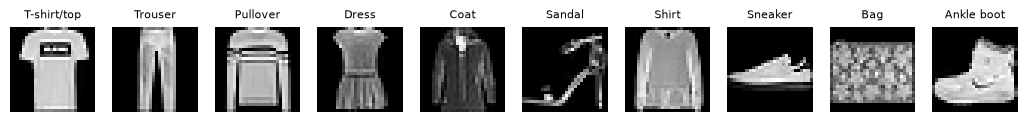

In [6]:
BASE_URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
FILES = {                                         # file -> MD5 checksum published with the dataset
    "train-images-idx3-ubyte.gz": "8d4fb7e6c68d591d4c3dfef9ec88bf0d",
    "train-labels-idx1-ubyte.gz": "25c81989df183df01b3e8a0aad5dffbe",
    "t10k-images-idx3-ubyte.gz": "bef4ecab320f06d8554ea6380940ec79",
    "t10k-labels-idx1-ubyte.gz": "bb300cfdad3c16e7a12a480ee83cd310",
}
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]


def download(data_dir: Path) -> None:
    data_dir.mkdir(parents=True, exist_ok=True)
    for name, expected_md5 in FILES.items():
        path = data_dir / name
        if not path.exists():
            urllib.request.urlretrieve(BASE_URL + name, path)
        if hashlib.md5(path.read_bytes()).hexdigest() != expected_md5:
            path.unlink()
            raise ValueError(f"{name}: checksum mismatch, file deleted")


def read_idx(path: Path) -> np.ndarray:
    """The raw format: a short header (16 bytes for images, 8 for labels), then one uint8 per pixel or label."""
    data = gzip.open(path).read()
    if "images" in path.name:
        return np.frombuffer(data, np.uint8, offset=16).reshape(-1, 28, 28).copy()
    return np.frombuffer(data, np.uint8, offset=8).copy()


download(DATA_DIR)
train_images, train_labels = read_idx(DATA_DIR / "train-images-idx3-ubyte.gz"), read_idx(DATA_DIR / "train-labels-idx1-ubyte.gz")
test_images, test_labels = read_idx(DATA_DIR / "t10k-images-idx3-ubyte.gz"), read_idx(DATA_DIR / "t10k-labels-idx1-ubyte.gz")
print("train", train_images.shape, train_images.dtype, "| test", test_images.shape)
print("images per class:", np.bincount(train_labels).tolist())

fig, axes = plt.subplots(1, 10, figsize=(13, 1.8))
for k, ax in enumerate(axes):
    ax.imshow(train_images[np.argmax(train_labels == k)], cmap="gray")
    ax.set_title(CLASSES[k], fontsize=8)
    ax.axis("off")
plt.show()

Exactly 6,000 training images per class, so the classes are balanced and accuracy is a fair metric.

A **Dataset** needs two methods: `__len__` (how many examples) and `__getitem__` (example number `i`). That's a **map-style** dataset.
An **IterableDataset** yields examples one after another instead, for data too big to index, such as a stream of web pages for LLM training.

The images stay as uint8 in memory (4x smaller than float32) and each one is converted when it's requested.

In [7]:
class FashionMNISTDataset(Dataset):
    def __init__(self, images: np.ndarray, labels: np.ndarray):
        self.images = torch.from_numpy(images)              # uint8 (n, 28, 28)
        self.labels = torch.from_numpy(labels).long()       # CrossEntropyLoss needs int64 labels

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, i: int) -> tuple[torch.Tensor, torch.Tensor]:
        return self.images[i].float() / 255, self.labels[i]     # pixels scaled to [0, 1]


full_train = FashionMNISTDataset(train_images, train_labels)
test_set = FashionMNISTDataset(test_images, test_labels)
image, label = full_train[0]
print(f"{len(full_train):,} examples | one item: image {tuple(image.shape)} {image.dtype}, label {label.item()} = {CLASSES[label]}")
print(f"memory: {full_train.images.nbytes / 1e6:.0f} MB as uint8, would be {full_train.images.nbytes * 4 / 1e6:.0f} MB as float32")

60,000 examples | one item: image (28, 28) torch.float32, label 9 = Ankle boot
memory: 47 MB as uint8, would be 188 MB as float32


# 6. SPLITS AND THE DATALOADER

- Split off a **validation set** from the training data to choose epochs and settings. Touch the **test set** once, at the very end.
- Compute normalization statistics (mean and std) on the **training split only**; using validation or test data would leak information.
- Deep learning rarely uses k-fold cross-validation: training even once is expensive, and datasets are usually large enough for one validation split.

| DataLoader argument | What it does |
|---|---|
| `batch_size` | examples per batch |
| `shuffle=True` | new order every epoch (training only) |
| `drop_last=True` | skip the last, smaller batch |
| `num_workers` | background processes that load batches while the model trains |
| `pin_memory=True` | faster copies to an NVIDIA GPU |
| `collate_fn` | how a list of examples becomes one batch (section 7) |
| `generator` | a seeded random stream, so the shuffle order is reproducible |

`num_workers > 0` starts new processes. On macOS and Windows those processes must be able to *import* the Dataset class,
so a class defined inside a notebook fails there. Training scripts (02.3) put the Dataset in a module and use workers.

In [8]:
train_set, val_set = random_split(full_train, [54_000, 6_000], generator=torch.Generator().manual_seed(0))

train_pixels = full_train.images[train_set.indices].float() / 255
mean, std = train_pixels.mean().item(), train_pixels.std().item()
print(f"train {len(train_set):,} | validation {len(val_set):,} | test {len(test_set):,} | pixel mean {mean:.4f}, std {std:.4f}")

BATCH_SIZE = 128
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, generator=torch.Generator().manual_seed(0))
val_loader = DataLoader(val_set, batch_size=512)
test_loader = DataLoader(test_set, batch_size=512)

images, labels = next(iter(train_loader))
print("one batch:", tuple(images.shape), images.dtype, "| labels", tuple(labels.shape), labels.dtype)
print("batches per epoch:", len(train_loader))

start = time.perf_counter()
for images, labels in train_loader:
    pass
print(f"loading one epoch of batches, no training: {time.perf_counter() - start:.2f} s")

train 54,000 | validation 6,000 | test 10,000 | pixel mean 0.2863, std 0.3531
one batch: (128, 28, 28) torch.float32 | labels (128,) torch.int64
batches per epoch: 421


loading one epoch of batches, no training: 0.25 s


The DataLoader turned single (28, 28) images into batches of (128, 28, 28). Loading one epoch takes 0.25 s on its own.
Compare it with the epoch times in section 9: if loading is a large share, the GPU waits for data, and more `num_workers` is the fix.

# 7. PADDING VARIABLE-LENGTH SEQUENCES

The default `collate_fn` stacks examples, so they must all have the same shape. Text doesn't: sentences have different numbers of tokens.
The fix is a custom `collate_fn` that **pads** every sequence to the longest one in the batch and returns an **attention mask**
(1 = real token, 0 = padding) so the model can ignore the padding. Every transformer batch is built this way.

In [9]:
sentences = [[5, 12, 7], [8, 3], [9, 4, 11, 2, 6]]                  # token ids, different lengths
token_data = [(torch.tensor(s), torch.tensor(i % 2)) for i, s in enumerate(sentences)]
show_error(lambda: next(iter(DataLoader(token_data, batch_size=3))))


def pad_collate(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(s) for s in sequences])
    ids = nn.utils.rnn.pad_sequence(sequences, batch_first=True, padding_value=0)
    mask = torch.arange(ids.shape[1]) < lengths[:, None]             # True for real tokens
    return ids, mask, torch.stack(labels)


ids, mask, labels = next(iter(DataLoader(token_data, batch_size=3, collate_fn=pad_collate)))
print("padded ids:\n", ids, "\nattention mask:\n", mask.int())

RuntimeError: stack expects each tensor to be equal size, but got [3] at entry 0 and [2] at entry 1
padded ids:
 tensor([[ 5, 12,  7,  0,  0],
        [ 8,  3,  0,  0,  0],
        [ 9,  4, 11,  2,  6]]) 
attention mask:
 tensor([[1, 1, 1, 0, 0],
        [1, 1, 0, 0, 0],
        [1, 1, 1, 1, 1]], dtype=torch.int32)


The default collate fails because it can't stack lengths 3, 2 and 5. The custom one pads to length 5, and the mask marks the real tokens.
Sorting or grouping sentences by length before batching (**bucketing**) reduces the wasted padding.

# 8. LOSS FUNCTIONS

| Task | Model output | Loss |
|---|---|---|
| regression | one raw number per example | `MSELoss`; `L1Loss` or `HuberLoss` when there are outliers |
| binary or multi-label | raw logits | `BCEWithLogitsLoss` (`pos_weight=` for imbalanced classes) |
| multi-class | raw logits, shape (n, classes) | `CrossEntropyLoss` (`weight=`, `label_smoothing=`, `ignore_index=`) |
| next-token prediction (LLMs) | logits, shape (n · tokens, vocabulary) | `CrossEntropyLoss` with `ignore_index=-100` for padding |
| distillation (folder 13) | log-probabilities vs teacher probabilities | `KLDivLoss` |

Losses take **raw logits**, not probabilities, because they combine the sigmoid or softmax with the log in one numerically stable formula.
Applying `sigmoid` yourself and then `BCELoss` breaks on large logits:

In [10]:
for logit, target in [(100.0, 0.0), (-200.0, 1.0)]:
    z = torch.tensor([logit], requires_grad=True)
    t = torch.tensor([target])
    nn.BCELoss()(torch.sigmoid(z), t).backward()
    unstable_loss, unstable_grad = nn.BCELoss()(torch.sigmoid(z), t).item(), z.grad.item()
    z.grad = None
    stable = nn.BCEWithLogitsLoss()(z, t)
    stable.backward()
    print(f"logit {logit:>6}, label {target:.0f}:  sigmoid + BCELoss = {unstable_loss:5.1f} (gradient {unstable_grad:4.1f})"
          f"   BCEWithLogitsLoss = {stable.item():5.1f} (gradient {z.grad.item():4.1f})")

logit  100.0, label 0:  sigmoid + BCELoss = 100.0 (gradient  0.0)   BCEWithLogitsLoss = 100.0 (gradient  1.0)
logit -200.0, label 1:  sigmoid + BCELoss = 100.0 (gradient -0.0)   BCEWithLogitsLoss = 200.0 (gradient -1.0)


Both examples are badly wrong, so the model should learn a lot from them. `sigmoid` rounds to exactly 1.0 or 0.0 in float32, so `BCELoss`
gives a gradient of 0: nothing is learned, and for the second example the loss is capped at 100 instead of the true 200.
`BCEWithLogitsLoss` gets both right, with a gradient of ±1.

`ignore_index` lets one tensor of targets contain padding: positions marked −100 are left out of the loss.

In [11]:
torch.manual_seed(0)
logits = torch.randn(2, 4, 6)                                       # 2 sentences, 4 positions, vocabulary of 6
targets = torch.tensor([[1, 3, 2, -100], [4, 0, -100, -100]])         # -100 = padding
loss = nn.functional.cross_entropy(logits.reshape(-1, 6), targets.reshape(-1), ignore_index=-100)
real = targets != -100
print(f"with ignore_index: {loss.item():.4f} | the 5 real tokens only: {nn.functional.cross_entropy(logits[real], targets[real]).item():.4f}")

with ignore_index: 1.8291 | the 5 real tokens only: 1.8291


# 9. THE TRAINING LOOP

Two functions that almost every PyTorch project has in some form.
- The loss is summed as `loss × batch size` and divided by the number of examples, so a smaller last batch doesn't skew the average.
- `loss.item()` turns the loss into a plain number. On a GPU, each `.item()` waits for the GPU to finish;
  fast training loops add up losses on the GPU and call `.item()` once per epoch.

In [12]:
def train_one_epoch(model, loader, loss_fn, optimizer, device) -> float:
    model.train()
    total, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(y)
        n += len(y)
    return total / n


@torch.inference_mode()
def evaluate(model, loader, loss_fn, device) -> tuple[float, float]:
    model.eval()
    total, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total += loss_fn(logits, y).item() * len(y)
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)
    return total / n, correct / n

Training for 15 epochs with Adam (folder 03), keeping a copy of the weights from the epoch with the best validation accuracy.
It runs on the CPU, because section 10 shows that the CPU is faster for a model this small.

epoch  1  train loss 0.5371  val loss 0.3783  val acc 0.8560  0.9 s


epoch  2  train loss 0.3907  val loss 0.3509  val acc 0.8683  0.9 s


epoch  3  train loss 0.3553  val loss 0.3465  val acc 0.8707  0.8 s


epoch  4  train loss 0.3316  val loss 0.3450  val acc 0.8682  0.8 s


epoch  5  train loss 0.3154  val loss 0.3207  val acc 0.8840  0.9 s


epoch  6  train loss 0.3018  val loss 0.3248  val acc 0.8740  0.9 s


... (5 outputs left out)

epoch 12  train loss 0.2427  val loss 0.3080  val acc 0.8950  0.9 s


epoch 13  train loss 0.2405  val loss 0.2995  val acc 0.8998  0.9 s


epoch 14  train loss 0.2348  val loss 0.3046  val acc 0.8920  0.9 s


epoch 15  train loss 0.2282  val loss 0.2984  val acc 0.8913  0.9 s

best validation accuracy 0.8998 at epoch 13


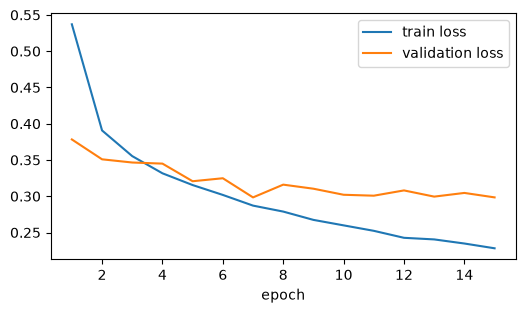

In [13]:
device = torch.device("cpu")
torch.manual_seed(0)
model = MLP(dropout=0.2, mean=mean, std=std).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

history, best_acc = [], 0.0
for epoch in range(1, 16):
    start = time.perf_counter()
    train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, loss_fn, device)
    history.append((train_loss, val_loss))
    if val_acc > best_acc:
        best_acc, best_epoch, best_state = val_acc, epoch, copy.deepcopy(model.state_dict())
    print(f"epoch {epoch:>2}  train loss {train_loss:.4f}  val loss {val_loss:.4f}  val acc {val_acc:.4f}  {time.perf_counter() - start:.1f} s")
print(f"\nbest validation accuracy {best_acc:.4f} at epoch {best_epoch}")

plt.figure(figsize=(6, 3.2))
plt.plot(range(1, 16), [h[0] for h in history], label="train loss")
plt.plot(range(1, 16), [h[1] for h in history], label="validation loss")
plt.xlabel("epoch")
plt.legend()
plt.show()

Validation accuracy climbs from 0.856 after epoch 1 to a best of 0.900 at epoch 13, then levels off around 0.89. The training loss keeps falling (0.537 → 0.228), but the validation loss stops improving at about 0.30 after epoch 7. That growing gap is the start of overfitting, which is why the best epoch's weights are kept instead of the last ones. Each epoch takes under a second.

# 10. CPU OR GPU?

A GPU only helps when there's enough work per step to hide its fixed costs: launching work, copying each batch from CPU memory,
and waiting for results (every `.item()` in the loop waits). Two measurements:
- a **real epoch**: batches come from the DataLoader on the CPU and are copied to the device every step;
- **compute only**: the batch is already on the device, so only the model's own work is timed.

In [14]:
def get_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def synchronize(device: torch.device) -> None:
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


def ms_per_step(device: torch.device, batch_size: int, hidden: tuple[int, ...], steps: int = 50) -> float:
    torch.manual_seed(0)
    m = MLP(hidden=hidden).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    x, y = torch.rand(batch_size, 28, 28, device=device), torch.randint(0, 10, (batch_size,), device=device)
    for step in range(steps + 5):
        if step == 5:                                   # skip warm-up steps
            synchronize(device)
            start = time.perf_counter()
        opt.zero_grad()
        nn.functional.cross_entropy(m(x), y).backward()
        opt.step()
    synchronize(device)
    return (time.perf_counter() - start) / steps * 1000


def epoch_seconds(device: torch.device) -> float:
    torch.manual_seed(0)
    m = MLP(mean=mean, std=std).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    start = time.perf_counter()
    train_one_epoch(m, train_loader, loss_fn, opt, device)
    return time.perf_counter() - start


gpu = get_device()
print(f"real epoch, this notebook's model:  cpu {epoch_seconds(torch.device('cpu')):.2f} s   {gpu.type} {epoch_seconds(gpu):.2f} s\n")
print("compute only, ms per training step:")
for hidden in [(256, 128), (4096, 4096)]:
    for batch_size in [128, 2048]:
        cpu_ms, gpu_ms = ms_per_step(torch.device("cpu"), batch_size, hidden), ms_per_step(gpu, batch_size, hidden)
        print(f"hidden {str(hidden):<12} batch {batch_size:>4}:  cpu {cpu_ms:6.2f} ms   {gpu.type} {gpu_ms:6.2f} ms   -> {'cpu' if cpu_ms < gpu_ms else gpu.type} wins")

real epoch, this notebook's model:  cpu 0.76 s   mps 1.21 s

compute only, ms per training step:
hidden (256, 128)   batch  128:  cpu   1.20 ms   mps   0.63 ms   -> mps wins


hidden (256, 128)   batch 2048:  cpu   3.00 ms   mps   1.40 ms   -> mps wins


hidden (4096, 4096) batch  128:  cpu  22.48 ms   mps   9.80 ms   -> mps wins


hidden (4096, 4096) batch 2048:  cpu 128.70 ms   mps  88.22 ms   -> mps wins


On compute alone, the Mac's GPU is about 2x faster at every size (0.63 ms against 1.20 ms per step for this notebook's model). But a real epoch is faster on the CPU: 0.76 s against 1.21 s. Each of the 421 steps copies a batch to the GPU and waits for `.item()`, and those fixed costs outweigh the 0.6 ms saved per step.

With the bigger model (two layers of 4,096), each step has far more work (9.8 ms against 22.5 ms), so the fixed costs matter less and the GPU pays off. On NVIDIA GPUs, `pin_memory=True` with `.to(device, non_blocking=True)` hides much of the copy time. The rule: time the real loop, not just the maths.

# 11. SAVING, LOADING AND RESUMING

- **`state_dict()`** is a dictionary of every parameter and buffer by name. Save that, not the whole model object:
  `torch.save(model)` pickles a reference to your class's file path, so it breaks when the code is moved or renamed.
- **Two kinds of checkpoint:** a *model checkpoint* for serving (weights + config + class names) and a *training checkpoint* for resuming
  (also the optimizer state, the epoch and the random number generator states).
- **Security:** `torch.load` uses pickle, which can run any code hidden in the file. `weights_only=True` (the default since PyTorch 2.6) only loads tensors and
  basic types. **safetensors**, the Hugging Face format, stores raw tensors only, so it can't contain code, and it loads fast.
- **`map_location="cpu"`** loads a checkpoint saved on a GPU onto a machine without one.

In [15]:
MODEL_DIR.mkdir(exist_ok=True)
model.load_state_dict(best_state)                         # back to the best epoch
torch.save({"model": model.state_dict(), "config": {"hidden": [256, 128], "dropout": 0.2},
            "classes": CLASSES, "epoch": best_epoch, "val_acc": best_acc}, MODEL_DIR / "fashion_mlp.pt")
print("state_dict keys:", list(model.state_dict().keys()))

ckpt = torch.load(MODEL_DIR / "fashion_mlp.pt", map_location="cpu", weights_only=True)
restored = MLP(hidden=tuple(ckpt["config"]["hidden"]), dropout=ckpt["config"]["dropout"])
restored.load_state_dict(ckpt["model"])
print(f"restored: mean buffer {restored.mean.item():.4f}, validation accuracy {evaluate(restored, val_loader, loss_fn, device)[1]:.4f} (saved: {ckpt['val_acc']:.4f})")

from safetensors.torch import load_file, save_file

save_file(model.state_dict(), MODEL_DIR / "fashion_mlp.safetensors")
same = all(torch.equal(v, load_file(MODEL_DIR / "fashion_mlp.safetensors")[k]) for k, v in model.state_dict().items())
print(f"safetensors round trip identical: {same}, file size {(MODEL_DIR / 'fashion_mlp.safetensors').stat().st_size / 1e6:.2f} MB")

state_dict keys: ['mean', 'std', 'net.0.weight', 'net.0.bias', 'net.3.weight', 'net.3.bias', 'net.6.weight', 'net.6.bias']
restored: mean buffer 0.2863, validation accuracy 0.8998 (saved: 0.8998)
safetensors round trip identical: True, file size 0.94 MB


The restored model scores exactly what was saved, and its normalization buffers came back with the weights.

**Resuming exactly.** A run that stops after epoch 1 and resumes should end up with the same weights as a run that never stopped.
That needs the model, the optimizer state (Adam keeps two running averages per weight), and the random states for dropout and shuffling.
The test below compares an uninterrupted 2-epoch run, a proper resume, and a resume that restores only the weights.

In [16]:
def new_run():
    torch.manual_seed(0)
    m = MLP(dropout=0.2, mean=mean, std=std)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    gen = torch.Generator().manual_seed(0)
    return m, opt, gen, DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, generator=gen)


m, opt, gen, loader = new_run()                            # A: two epochs without stopping
for _ in range(2):
    train_one_epoch(m, loader, loss_fn, opt, device)
uninterrupted = m.state_dict()

m, opt, gen, loader = new_run()                            # B: one epoch, save, start over, load, one more epoch
train_one_epoch(m, loader, loss_fn, opt, device)
torch.save({"model": m.state_dict(), "optimizer": opt.state_dict(), "epoch": 1,
            "torch_rng": torch.get_rng_state(), "loader_rng": gen.get_state()}, MODEL_DIR / "train_ckpt.pt")
m, opt, gen, loader = new_run()
ckpt = torch.load(MODEL_DIR / "train_ckpt.pt", weights_only=True)
m.load_state_dict(ckpt["model"])
opt.load_state_dict(ckpt["optimizer"])
torch.set_rng_state(ckpt["torch_rng"])
gen.set_state(ckpt["loader_rng"])
train_one_epoch(m, loader, loss_fn, opt, device)
resumed = m.state_dict()

m, opt, gen, loader = new_run()                            # C: restore only the weights
m.load_state_dict(ckpt["model"])
train_one_epoch(m, loader, loss_fn, opt, device)
weights_only_resume = m.state_dict()

diff = lambda a, b: max((a[k] - b[k]).abs().max().item() for k in a)
print(f"A vs B (full resume):         max weight difference {diff(uninterrupted, resumed):.1e}")
print(f"A vs C (weights only):        max weight difference {diff(uninterrupted, weights_only_resume):.1e}")
print(f"file sizes: weights only {(MODEL_DIR / 'fashion_mlp.safetensors').stat().st_size / 1e6:.2f} MB, "
      f"training checkpoint {(MODEL_DIR / 'train_ckpt.pt').stat().st_size / 1e6:.2f} MB")

A vs B (full resume):         max weight difference 0.0e+00
A vs C (weights only):        max weight difference 2.2e-01
file sizes: weights only 0.94 MB, training checkpoint 2.84 MB


The full resume matches the uninterrupted run exactly (difference 0.0). Restoring only the weights ends up 0.22 away: Adam restarted with empty running averages, and the dropout and shuffle order changed.

The training checkpoint is 2.84 MB against 0.94 MB for the weights alone. Adam stores two extra numbers per weight, so it triples the memory, which matters a lot for large models (folder 03).

# 12. TEST SET AND PREDICTIONS

The test set is used once, with the final model. A `predict` function returns class probabilities; for a single image, add a batch dimension with `unsqueeze(0)`.

In [17]:
@torch.inference_mode()
def predict(model: nn.Module, images: torch.Tensor) -> torch.Tensor:
    """Images (n, 28, 28) with pixels in [0, 1] -> class probabilities (n, 10)."""
    model.eval()
    return torch.softmax(model(images), dim=1)


test_loss, test_acc = evaluate(model, test_loader, loss_fn, device)
print(f"test accuracy {test_acc:.4f} (validation {best_acc:.4f})")

probs = predict(model, test_set.images.float() / 255)
preds = probs.argmax(dim=1)
labels = test_set.labels
for k in torch.tensor([(preds[labels == k] == k).float().mean() for k in range(10)]).argsort()[:3].tolist():
    wrong = preds[(labels == k) & (preds != k)]
    print(f"  weakest: {CLASSES[k]:<12} accuracy {(preds[labels == k] == k).float().mean():.3f}, most often mistaken for {CLASSES[wrong.mode().values.item()]}")

one = predict(model, test_set[0][0].unsqueeze(0))[0]
print(f"\nfirst test image: predicted {CLASSES[one.argmax()]} with probability {one.max():.3f}, true label {CLASSES[test_set[0][1]]}")

test accuracy 0.8858 (validation 0.8998)
  weakest: Shirt        accuracy 0.664, most often mistaken for T-shirt/top
  weakest: Pullover     accuracy 0.792, most often mistaken for Coat
  weakest: Coat         accuracy 0.830, most often mistaken for Shirt

first test image: predicted Ankle boot with probability 0.986, true label Ankle boot


Test accuracy is 0.886, a little below the validation score of 0.900. Picking the best of 15 epochs on the validation set makes that score slightly optimistic, which is exactly why a separate test set is kept.

The weakest class is Shirt (0.664), most often mistaken for T-shirt/top, and Pullover and Coat are confused with each other. These look alike at 28×28 pixels, and an MLP flattens the image, ignoring its 2D structure. A CNN (folder 04) does better.

# 13. TRADE-OFFS

| Decision | Options | What you gain and what you pay | Usual choice |
|---|---|---|---|
| Where to normalize inputs | in the Dataset / inside the model (buffers) | Dataset: flexible, but serving code must repeat it exactly. Model: travels with the checkpoint, can't be forgotten | inside the model, or a shared preprocessing function |
| How data is held | all in memory / read from disk per item / streamed (`IterableDataset`) | memory: fastest, limited by RAM. Disk: any size, needs workers to keep up. Streaming: unlimited, but no random access or exact length | memory if it fits; streaming for LLM-scale data |
| `num_workers` | 0 / several | 0: simple, easy to debug, but loading blocks training. Several: loading runs in parallel, but uses more RAM and processes | 0 to debug; 4–8 (or the number of CPU cores) for real training |
| Saving format | whole model pickle / `state_dict` with `torch.save` / safetensors | pickle: breaks on code changes and can run code. `state_dict`: standard, safe with `weights_only=True`. safetensors: no code at all, fast, used on the Hugging Face Hub | `state_dict` for training checkpoints, safetensors for shared weights |
| Which weights to keep | last epoch / best validation epoch | last: simple, but may be overfitted. Best: better model, needs a validation set | best, plus the last training checkpoint for resuming |
| Device for small models | CPU / GPU | the GPU's fixed costs outweigh the maths for tiny models (section 10) | measure; GPUs win as models and batches grow |
| Binary loss | `sigmoid` + `BCELoss` / `BCEWithLogitsLoss` | the first breaks on large logits (section 8) | `BCEWithLogitsLoss` |
| Validation | one split / k-fold | one split: cheap. k-fold: steadier estimate, but k times the training cost | one split in deep learning |

# 14. INTERVIEW QUESTIONS

### Q1. Walk me through a PyTorch training loop, in 30 seconds.
A Dataset returns single examples and a DataLoader batches and shuffles them. For each batch: move it to the device, `zero_grad()`, forward pass,
compute the loss, `backward()`, `optimizer.step()`. After each epoch, evaluate with `model.eval()` and `inference_mode()`, and save a checkpoint when validation improves.

### Q2. Why call `model(x)` instead of `model.forward(x)`?
`__call__` runs registered hooks around `forward`. Calling `forward` directly skips them, which silently breaks tools that rely on hooks.

### Q3. What's the difference between a parameter and a buffer?
Both are saved in the `state_dict` and moved by `.to(device)`. Parameters get gradients and are updated by the optimizer; buffers don't.
Examples of buffers: BatchNorm running statistics, attention masks, normalization constants.

### Q4. Why is a plain Python list of layers a bug? `nn.Sequential` vs `nn.ModuleList`?
PyTorch only registers modules stored directly as attributes or inside its own containers, so layers in a list are not trained, moved or saved.
`Sequential` runs its layers in order; `ModuleList` just holds them and you write the loop in `forward`.

### Q5. What do `model.train()` and `model.eval()` change?
They switch dropout (on or off) and BatchNorm (batch statistics or running averages). They don't affect gradient tracking; for that use `torch.inference_mode()` or `torch.no_grad()`.

### Q6. Dataset vs DataLoader? Map-style vs iterable datasets?
A Dataset returns one example; a DataLoader batches, shuffles and loads in parallel. A map-style dataset has `__len__` and `__getitem__` (random access);
an IterableDataset yields examples in sequence, for streams too big to index.

### Q7. How do you batch sequences of different lengths?
A custom `collate_fn` pads them to the longest in the batch and returns an attention mask so the model ignores the padding.
Grouping similar lengths together (bucketing) reduces wasted padding.

### Q8. What do `num_workers` and `pin_memory` do?
`num_workers` loads batches in background processes so the GPU doesn't wait for data. `pin_memory` puts batches in page-locked memory
for faster, asynchronous copies to an NVIDIA GPU (used with `.to(device, non_blocking=True)`).

### Q9. Why do `CrossEntropyLoss` and `BCEWithLogitsLoss` take logits instead of probabilities?
They combine softmax or sigmoid with the log in one numerically stable formula. Computing probabilities first can round to exactly 0 or 1,
which gives infinite or capped losses and zero gradients.

### Q10. What is `ignore_index=-100` for?
Targets marked −100 are skipped in the loss. LLM training uses it for padding, and to skip the prompt tokens so the model only learns from the answer.

### Q11. What must a checkpoint contain to resume training exactly?
The model `state_dict`, the optimizer `state_dict` (Adam's running averages), the learning-rate scheduler state, the epoch or step, and the random number generator states.
Restoring only the weights restarts the optimizer from zero and changes the run.

### Q12. `state_dict` vs `torch.save(model)`? Why `weights_only=True` or safetensors?
`torch.save(model)` pickles a reference to the class, which breaks when code is moved. Pickle files can also run arbitrary code when loaded.
`weights_only=True` loads only tensors and basic types; safetensors contains only raw tensors, so it is safe and fast.

### Q13. Why weight the loss by batch size when averaging over an epoch?
The last batch is usually smaller. A plain mean of batch losses would give its examples more weight than the others.

### Q14. Why can training on a GPU be slower than on the CPU?
Each GPU operation has a fixed launch cost and data must be copied over. With a tiny model or batch, that overhead is bigger than the time saved on the maths.

### Q15. Training is slow. How do you find out whether data loading is the bottleneck?
Time one pass over the DataLoader without training and compare it with a full epoch, or watch GPU utilization. If loading is a large share,
add `num_workers`, use `pin_memory`, move preprocessing out of `__getitem__`, or store the data in a faster format.

# 15. IN MY OWN WORDS

Write this from memory, without looking above:

- The five lines inside every training step, in order:
- Parameter vs buffer, with an example of each:
- What `train()` / `eval()` change and what they don't:
- How to batch sentences of different lengths:
- What goes into a checkpoint that can resume training exactly: